1. Imports Python libraries needed for cleaning and NLP-work
* regex cleaning (re, string)
* frequency (collections)
* plotting (matplotlib, wordcloud)
* dataframe operations (numpy, pandas)
* non-parametric stats (scipy.stats.kruskal)
* vectorization and models (sklearn)
* NLP processing (nltk,spacy)
  
2. Downloads NLTK data bundles 
3. Initializes the PorterStemmer and stopword list
4. Loads spaCy’s English pipeline - en_core_web_sm
5. reads in the dataset friends.csv into a pandas df for processing
6. extracts names of unique speakers, cleans whitespace, and formats properly to continue
7. create a gazetteer of unique speakers and list of secondary characters coming from prior knowledge and standardises to lowercase
8. define a dictionary mapping of character nicknames and surnames
9. define key-value pairs of conversational contractions and slang into multi-word forms
10. create set of conversational filler words specific to dialogue and unions them with standard stopwords so they don't dominate later metrics
11. def strip_stage_directions(text):strips non-spoken script actions in () / [], collapses multiple whitespace characters into single spaces
12. def expand_contractions(text): replaces in with ing(walkin - walking),curly quotes to apostrophes,lowercases, and expands slang
13. def stem_to_lexeme_mapper:maps stemmed tokens to their frequently occurring unstemmed full word (laughing and not laughin)


In [1]:
import re
import string
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import kruskal
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer, TfidfVectorizer
from wordcloud import WordCloud

import nltk
from nltk.corpus import stopwords, wordnet
from nltk.stem import PorterStemmer
from nltk.tokenize import sent_tokenize, word_tokenize

import spacy
from spacy.pipeline import EntityRuler
import networkx as nx
import seaborn as sns

for resource in ["stopwords", "punkt", "punkt_tab", "wordnet", "averaged_perceptron_tagger"]:
    nltk.download(resource, quiet=True)

stemmer = PorterStemmer()
nltk_stopwords = set(stopwords.words("english"))

nlp = spacy.load("en_core_web_sm")
df_raw = pd.read_csv("friends.csv")

# Additional info needed for context-building - gazetteers, aliases, and contraction dictionaries
# extract unique speakers for a speaker gazetteer
all_speakers = set(df_raw["Speaker"].dropna().str.strip().str.title().unique())
# add secondary characters from Friends per personal knowledge
friends_character_gazetteer = all_speakers.union({
    "Mike", "Gunther", "Janine", "Emily", "Carol", "Susan","Estelle", "Richard", "Charlie", "Kathy", "Jill", "Amy",
    "Pete", "Tag", "Mona", "Paul", "Erica", "David", "Frank","Janice", "Treeger", "Ursula", "Kip", "Heckles"})

# make everything lowercase for standardisation
gazetteer_lower = {name.lower() for name in friends_character_gazetteer}

# alias mapping since the same person could have different variations of their name
name_alias_map = {
    "rach": "rachel",
    "pheebs": "phoebe","phoebs": "phoebe",
    "chan": "chandler", "bing": "chandler",
    "mon": "monica",
    "joe": "joey", "joseph": "joey","tribbiani": "joey","joey tribbiani":"joey"}

# dialogue  mapping so conversational slang is not misinterpreted
contractions_dict = {
    r"\bc'mon\b": "come on", r"\bgonna\b": "going to", r"\bwanna\b": "want to",
    r"\bdunno\b": "do not know", r"\bgotta\b": "got to", r"\b'em\b": "them",
    r"\bain't\b": "is not", r"\bdon't\b": "do not", r"\bdoesn't\b": "does not",
    r"\bdidn't\b": "did not", r"\bcan't\b": "cannot", r"\bwon't\b": "will not",
    r"\bisn't\b": "is not", r"\baren't\b": "are not", r"\bcouldn't\b": "could not",
    r"\bwouldn't\b": "would not", r"\bshouldn't\b": "should not", r"\bi'm\b": "i am",
    r"\byou're\b": "you are", r"\bhe's\b": "he is", r"\bshe's\b": "she is",
    r"\bit's\b": "it is", r"\bwe're\b": "we are", r"\bthey're\b": "they are",r"(?<!\w)'em\b": "them",
    r"\bthere's\b": "there is", r"\bthat's\b": "that is", r"\bwhat's\b": "what is", r"\bwho's\b": "who is"}

#  fillers and dialogue noise stopwords
spoken_fillers = {"hey", "yeah", "know", "oh", "look", "right", "like", "get", "okay", "go", 
    "well", "na", "uh", "got", "ok", "gon", "wan", "think", "mean", "say", "see", 
    "come", "gonna", "wanna", "thing", "things", "something", "us", "would", "could",
    "take", "tell", "make", "let", "uhh", "yeahs", "ooh", "ah", "huh", "hi", "yes",
    "umm", "uhm", "woah", "alright", "somethin", "dunno", "naa", "noooo", "hmm",
    "dude", "man", "guys", "guy", "one", "really", "going", "would", "back", "said"}

# add these also to the more general stopword list 
custom_stopwords = nltk_stopwords.union(spoken_fillers)

def strip_stage_directions(text):
    if not isinstance(text, str): return ""
    text = re.sub(r"\([^)]*\)", "", text)
    text = re.sub(r"\[[^\]]*\]", "", text)
    return re.sub(r"\s+", " ", text).strip()

def fix_dropped_g(t):
    return re.sub(r"\b(\w{2,})in'(?=\W|$)", r"\1ing", t)

def expand_contractions(text):
    t = str(text).lower().replace("’", "'").replace("‘", "'")
    for pattern, replacement in contractions_dict.items():
        t = re.sub(pattern, replacement, t)
    return fix_dropped_g(t)

def stem_to_lexeme_mapper(stemmed_tokens, original_tokens):
    mapping = defaultdict(Counter)
    for stem, orig in zip(stemmed_tokens, original_tokens): mapping[stem][orig.lower()] += 1
    stem2lexeme = {}
    for stem, counts in mapping.items(): stem2lexeme[stem] = counts.most_common(1)[0][0]
    return stem2lexeme

## Preprocessing

* identifies compound speakers (Joey and Ross) or offshoots (Joey's Co-Star)
* counts non-standard apostrophes needing normalization
* verifies episode counts per season 

In [10]:
# data checks 
spk = df_raw["Speaker"].fillna("").str.strip()
print("lines where Joey is the speaker :", int((spk.str.lower() == "joey").sum()))
other = spk[spk.str.contains("joey", case=False) & (spk.str.lower() != "joey")]
print("other lines/labels that contain 'joey' but are not his lines):", other.value_counts().head(8).to_dict())
print("episodes per season in the file:", df_raw.groupby("Season")["Episode"].nunique().to_dict(), "-> total", df_raw[["Season", "Episode"]].drop_duplicates().shape[0])

lines where Joey is the speaker : 8047
other lines/labels that contain 'joey' but are not his lines): {'Chandler and Joey': 16, 'Joey and Chandler': 13, "Joey's Hand Twin": 13, 'Joey/Drake': 13, 'Joey and Ross': 10, "Joey's Co-Star": 6, 'CHANDLER and JOEY': 6, "Joey's Doctor": 6}
episodes per season in the file: {'Season-01': 24, 'Season-02': 23, 'Season-03': 25, 'Season-04': 23, 'Season-05': 23, 'Season-06': 23, 'Season-07': 23, 'Season-08': 23, 'Season-09': 23, 'Season-10': 15} -> total 225


### Which preprocessing step where
| Step | Q1 | Q2  | Q3 | Q4 |
|---|---|---|---|---|
| remove stage directions `( )/[ ]` | yes | yes | yes | yes |
| removing punctuation | no (needed for sentence splitting) | no - NER needs the original text | yes (`isalpha`) | yes |
| lower case | no | no - capital letters help NER | yes | yes |
| sentence / word tokenisation | sentences: `sent_tokenize`; words:regex| spaCy tokenizer | `word_tokenize` | `word_tokenize` |
| slang contraction / expansion | no - one spoken word = one word | no | yes | yes |
| stopwords (NLTK + fillers) | no - count everything spoken | NLTK only | NLTK + fillers | NLTK + fillers |
| Porter stemming | no | no - spaCy lemma | yes - stem to readable word for the clouds | no |
| POS tagging + NER | no | yes | no | no |

## Q1

1. strips stage directions
2. tokenizes text into sentences and words per episode
3. aggregates total word/sentence counts
4. calculates mean/median/std per season
5. Kruskal-Wallis test across seasons to determine whether line lengths deviate significantly over time

Episodes: 225 | episodes without Joey lines: 0
        sents  words  lines
mean     66.5  382.3   35.7
std      31.3  174.7   14.7
median   60.0  348.0   33.0

            episodes  words  words_sd  sents  sents_sd  lines  words_per_line
Season                                                                      
Season-01        24  254.0     108.8   44.6      16.8   25.9             9.6
Season-02        23  314.3     139.5   46.9      21.1   28.4            11.5
Season-03        25  322.0     117.5   52.2      18.3   31.0            10.4
Season-04        23  361.8     159.1   63.9      28.3   35.6            10.3
Season-05        23  423.1     190.6   79.0      37.2   40.5            10.4
Season-06        23  478.0     182.0   82.0      32.2   39.5            12.5
Season-07        23  425.0     185.4   80.2      32.9   40.5            10.3
Season-08        23  467.6     228.2   82.7      37.8   39.6            11.8
Season-09        23  396.8     163.9   64.5      29.7   37.8         

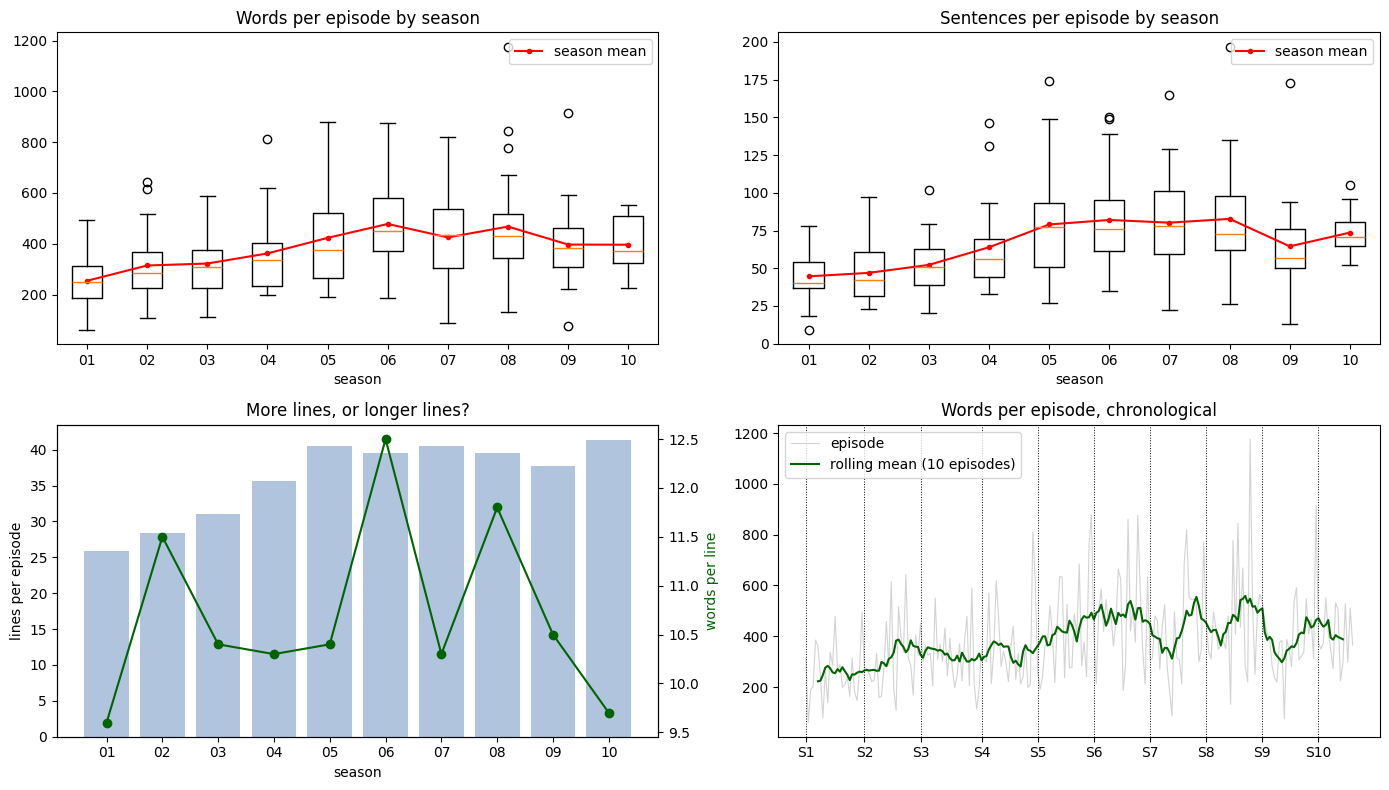

In [3]:
def count_words(text):
    return len(re.findall(r"[A-Za-z0-9]+(?:'[A-Za-z]+)*", str(text).replace("’", "'")))

def count_sents(text):
    return max(1, len(sent_tokenize(text))) if text else 0

q1 = df_raw.copy()
q1["clean_line"] = q1["Text"].apply(strip_stage_directions)                              
joey_lines = q1[q1["Speaker"].fillna("").str.strip().str.lower().eq("joey") & (q1["clean_line"] != "")].copy()
joey_lines["words"] = joey_lines["clean_line"].apply(count_words)
joey_lines["sents"] = joey_lines["clean_line"].apply(count_sents)
PUNCT = re.compile("[{}]".format(re.escape(string.punctuation)))
joey_lines["words_naive"] = joey_lines["Text"].apply(lambda t: len(word_tokenize(PUNCT.sub(" ", str(t).lower()))))   

# one row per episode of the CSV; an episode without Joey lines would count as 0 
all_eps = q1[["Season", "Episode"]].drop_duplicates()
ep = (joey_lines.groupby(["Season", "Episode"]).agg(lines=("clean_line", "count"), sents=("sents", "sum"), words=("words", "sum"),words_naive=("words_naive", "sum")).reset_index().merge(all_eps, on=["Season", "Episode"], how="right").fillna(0))
ep["words_per_line"] = ep["words"] / ep["lines"].replace(0, np.nan)
ep["season_num"] = ep["Season"].str.extract(r"(\d+)")[0].astype(int)
ep["ep_num"] = ep["Episode"].str.extract(r"(\d+)")[0].astype(int)
ep = ep.sort_values(["season_num", "ep_num"]).reset_index(drop=True)

print(f"Episodes: {len(ep)} | episodes without Joey lines: {(ep.lines == 0).sum()}")
print(ep[["sents", "words", "lines"]].agg(["mean", "std", "median"]).round(1).to_string())
season = ep.groupby("Season").agg(episodes=("Episode", "count"), words=("words", "mean"), words_sd=("words", "std"),sents=("sents", "mean"), sents_sd=("sents", "std"), lines=("lines", "mean"),words_per_line=("words_per_line", "mean")).round(1)
print("\n", season.to_string())

# Kruskal-Wallis test across seasons (no normality assumption) 
def kw(col):                                   
    H, p = kruskal(*[g[col].values for _, g in ep.groupby("Season")])
    return H, p, H / (len(ep) - 1)
Hw, pw, ew = kw("words"); Hs, ps, es = kw("sents")
print(f"\nKruskal-Wallis  words: H={Hw:.1f}, p={pw:.1e}, eps2={ew:.2f} | sentences: H={Hs:.1f}, p={ps:.1e}, eps2={es:.2f}")

order = sorted(ep["Season"].unique()); short = [s[-2:] for s in order]
fig, ax = plt.subplots(2, 2, figsize=(14, 8))
for a, col, ttl in [(ax[0, 0], "words", "Words per episode"), (ax[0, 1], "sents", "Sentences per episode")]:
    a.boxplot([ep.loc[ep.Season == s, col] for s in order]); 
    a.set_xticklabels(short)
    a.plot(range(1, len(order) + 1), season[col].values, "r.-", label="season mean"); 
    a.set_title(ttl + " by season"); 
    a.set_xlabel("season"); 
    a.legend()
    
a = ax[1, 0]; 
a.bar(range(len(order)), season["lines"].values, color="lightsteelblue", label="lines per episode")
a.set_xticks(range(len(order))); 
a.set_xticklabels(short); 
a.set_xlabel("season"); 
a.set_ylabel("lines per episode"); 
a.set_title("More lines, or longer lines?")
a2 = a.twinx(); 
a2.plot(range(len(order)), season["words_per_line"].values, "o-", color="darkgreen", label="words per line"); 
a2.set_ylabel("words per line", color="darkgreen")
a = ax[1, 1]; 
a.plot(ep["words"].values, color="lightgray", lw=0.8, label="episode"); 
a.plot(ep["words"].rolling(10, center=True).mean().values, color="darkgreen", label="rolling mean (10 episodes)")
starts = ep.groupby("season_num").head(1).index.tolist(); [a.axvline(s, color="k", ls=":", lw=0.7) for s in starts]
a.set_xticks(starts); 
a.set_xticklabels([f"S{i+1}" for i in range(len(starts))]); 
a.set_title("Words per episode, chronological"); 
a.legend()
plt.tight_layout(); 
plt.show()

* Over all 225 episodes across 10 seasons, Joey speaks in all of them
* On average, he says 66.5 sentences (sd 31.3) , 35.7 lines (sd 14.7) and 382 words (sd 175) per episode
* This does deviate across seasons: the mean number of words per episode goes from 254 (Season-01) to 478 (Season-06). 
* The differences are statistically significant (Kruskal–Wallis, words: H = 38.8, p = 1.2e-05; sentences: H = 58.0, p = 3.3e-09)
* Spread within season is large (sd of 106–228 words), so single episodes overlap a lot between seasons.
* For all three metrics, Mean > Median, indicating a right-skewed distribution
* Joey’s dialogue output increases from S1 (254.0 words/ep, 44.6 sents/ep, 25.9 lines/ep) to S6 (478.0 words/ep, 82.0 sents/ep, 39.5 lines/ep)
* Spoken output reaches its maximum between S6 and 8
* Later Seasons (Seasons 9–10) sees a slight reduction (396.8 and 396.1 words/ep), but remains  higher than early seasons.

1. Sentence Complexity remains stable, oscillating between 9.6 and 12.5 words per line
2. statistically significant difference in Joey's word count per episode across seasons (p < 0.001) with a moderate-to-strong non-parametric effect
approximately 17% of the variance in Joey's episode word count is explained by the season
3. statistically significant difference in Joey's sentence count per episode across seasons (p < 0.001) with a moderate-to-strong non-parametric effect
approximately 26% of the variance in Joey's episode sentence count is explained by the season

structural changes in script writing as Joey's character progressed from a secondary character to a primary comedic influence in the show

## Q2. Nouns and person names (POS and NER)

1. loads the pre-trained model en_core_web_sm
2. uses EntityRuler to explicitly tag show-specific locations and nicknames
3. use noise exclusion sets for misclassified interjections and non-entity slang words
4. filters dataset to Joey's non-empty spoken lines with stage directions removed
5. pass dialogues through spaCy pipeline 
6. go through every token and entity, collects lemmatized standard nouns ignoring stop words and NERs applying name-alias mapping
7. aggregates counts, prints summary tables, bar plots and WordClouds 

Total Nouns extracted: 9566 (2047 unique)
Total Entities extracted: 2400 (696 unique)
Top 7 Nouns: [('guy', 383), ('man', 206), ('thing', 195), ('time', 150), ('friend', 129), ('day', 118), ('woman', 113)]
Top 7 Entities: [('ross', 309), ('chandler', 224), ('rachel', 215), ('phoebe', 188), ('monica', 135), ('joey', 112), ('mike', 22)]


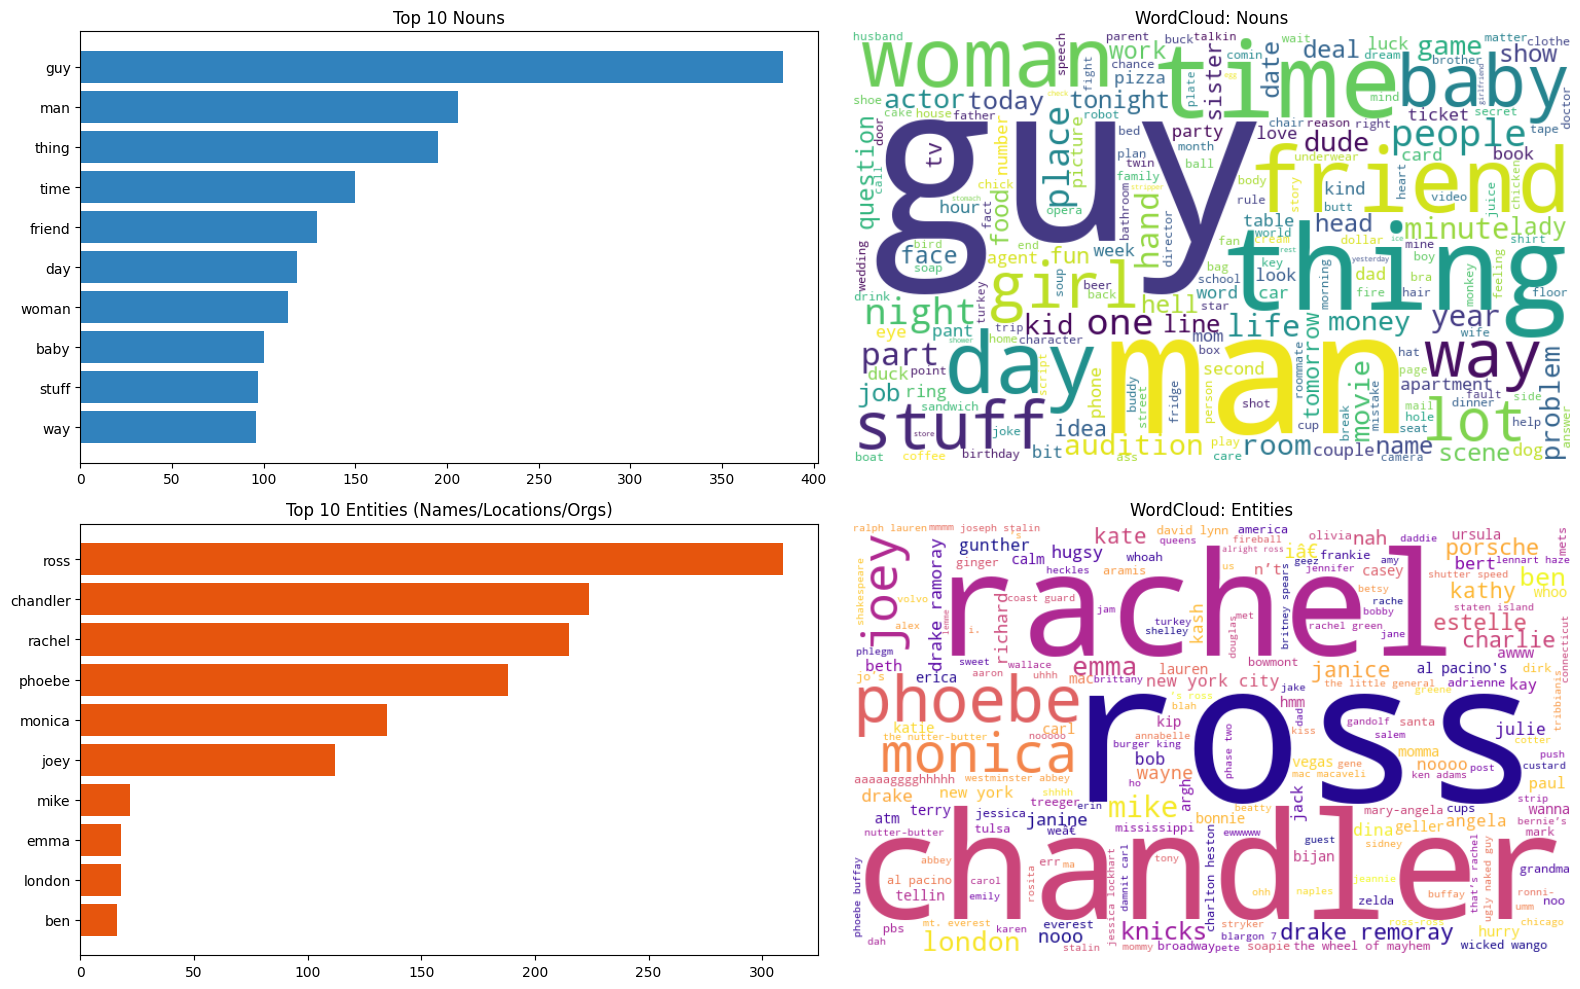

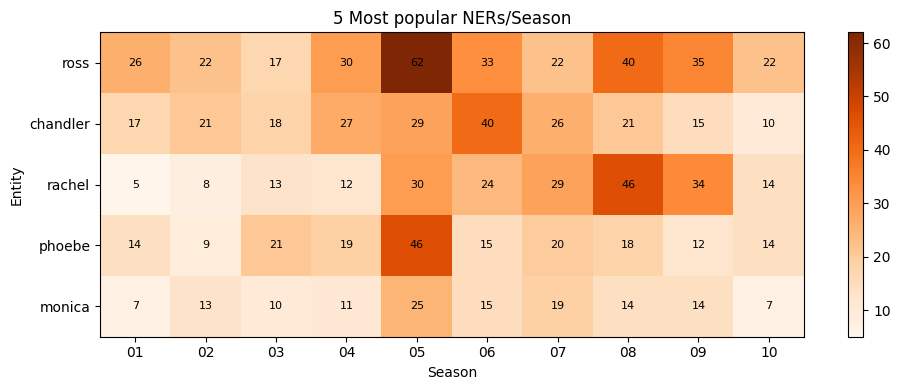

In [4]:
# init spaCy pipeline
nlp = spacy.load("en_core_web_sm")

# add EntityRuler 
ruler = nlp.add_pipe("entity_ruler", before="ner")
patterns = [
    {"label": "LOC",    "pattern": "Central Perk"},
    {"label": "PERSON", "pattern": "Chan-Chan Man"},
    {"label": "PERSON", "pattern": "Pheebs"},
    {"label": "PERSON", "pattern": "Rach"},
    {"label": "PERSON", "pattern": "Mon"}
]
ruler.add_patterns(patterns)

# noise sets
NOT_NOUNS = {"thank", "ohh", "ooh", "whoa", "huh", "hmm", "ah", "yeah"}
NON_PERSON = {"dude", "man", "guys", "guy", "kinda", "mornin", "alright", "congratulations","y'know","ya"}

# Joey's dialogue dataset
joey2 = df_raw[df_raw["Speaker"].fillna("").str.strip().str.lower() == "joey"].copy()
joey2["clean_line"] = joey2["Text"].apply(strip_stage_directions)
joey2 = joey2[joey2["clean_line"] != ""].reset_index(drop=True)

# process dialogue through spaCy 
docs = list(nlp.pipe(joey2["clean_line"], batch_size=250, disable=["parser"]))

# extract nouns and ners
nouns, entities_all = [], []

for season_label, doc in zip(joey2["Season"], docs):
    for tok in doc:
        if tok.pos_ == "NOUN" and tok.is_alpha:
            lem = tok.lemma_.lower()
            if lem not in nltk_stopwords and lem not in NOT_NOUNS and len(lem) > 1:
                nouns.append((season_label, lem))
    
    for ent in doc.ents:
        if ent.label_ in {"PERSON", "GPE", "LOC", "ORG", "FAC"}:
            clean_ent = ent.text.strip().lower()
            if clean_ent not in NON_PERSON and len(clean_ent) > 1:
                # apply alias map
                canonical = name_alias_map.get(clean_ent, clean_ent)
                entities_all.append((season_label, canonical, ent.label_))

# aggregate frequencies
noun_counts = Counter(lem for _, lem in nouns)
ent_counts = Counter(ent for _, ent, _ in entities_all)

print(f"Total Nouns extracted: {len(nouns)} ({len(noun_counts)} unique)")
print(f"Total Entities extracted: {len(entities_all)} ({len(ent_counts)} unique)")
print("Top 7 Nouns:", noun_counts.most_common(7))
print("Top 7 Entities:", ent_counts.most_common(7))

fig, ax = plt.subplots(2, 2, figsize=(16, 10))

top_nouns = pd.DataFrame(noun_counts.most_common(10), columns=["w", "n"]).sort_values("n")
ax[0, 0].barh(top_nouns["w"], top_nouns["n"], color="#3182bd")
ax[0, 0].set_title("Top 10 Nouns")
wc_nouns = WordCloud(width=700, height=420, background_color="white", colormap="viridis").generate_from_frequencies(noun_counts)
ax[0, 1].imshow(wc_nouns, interpolation="bilinear")
ax[0, 1].axis("off")
ax[0, 1].set_title("WordCloud: Nouns")

top_ents = pd.DataFrame(ent_counts.most_common(10), columns=["w", "n"]).sort_values("n")
ax[1, 0].barh(top_ents["w"], top_ents["n"], color="#e6550d")
ax[1, 0].set_title("Top 10 Entities (Names/Locations/Orgs)")
wc_ents = WordCloud(width=700, height=420, background_color="white", colormap="plasma").generate_from_frequencies(ent_counts)
ax[1, 1].imshow(wc_ents, interpolation="bilinear")
ax[1, 1].axis("off")
ax[1, 1].set_title("WordCloud: Entities")

plt.tight_layout()
plt.show()


top_entities = [ent for ent, _ in ent_counts.most_common(5)]
season_series = pd.Series([s for s, _, _ in entities_all], name="season")
entity_series = pd.Series([e for _, e, _ in entities_all], name="entity")
heat_ent = pd.crosstab(entity_series, season_series).reindex(top_entities).fillna(0)
plt.figure(figsize=(10, 4))
plt.imshow(heat_ent.values, cmap="Oranges", aspect="auto")
plt.xticks(range(heat_ent.shape[1]), [c[-2:] for c in heat_ent.columns])  # Extracts S01, S02... format
plt.yticks(range(heat_ent.shape[0]), heat_ent.index)
for i in range(heat_ent.shape[0]):
    for j in range(heat_ent.shape[1]): plt.text(j, i, int(heat_ent.values[i, j]), ha="center", va="center", fontsize=8)

plt.xlabel("Season")
plt.ylabel("Entity")
plt.title("5 Most popular NERs/Season")
plt.colorbar()
plt.tight_layout()
plt.show()

* Over 10 seasons Joey says 9,566 nouns (2,047 unique) - most frequent: guy (383), man (206), thing (195), time (150), friend (129)
* He mentions 2,400 person names (696 unique) - most frequent: ross (309), chandler (224), rachel (215), phoebe (188), monica (135)
* Aliases (rach, pheebs, joey tribbiani, ...) are merged.

1. informal gendered nouns (guy, man, woman) - casual, colloquial conversational style
2. addresses Ross most frequently, followed closely by best friend Chandler and Rachel 
3. outside the main six, Mike (Phoebe’s husband) is the most frequently mentioned named entity 
4. ners peak in Season 5 across - narrative arcs where Joey is a major player like Chandler and Monica's relationship
5. rachel peaks in season 8 during the storyline where Joey develops feelings for Rachel

## Q3. Most important words: per episode, per season, overall

1. clean input string, expand contractions, remove punctuation, map aliases, and filters out stopwords and tokens shorter than three chars
2. extract Joey's lines, apply tokenization, derive Porter stems, and build a dict mapping each stem back to its original word
3. group stemmed tokens into single document strings by Season or (Season, Episode) pair
4. convert document into a Bag-of-Words matrix, filter out rare terms, compute TF-IDF weights, and return feature names
5. build episode-level and season-level dataframes
6. sum global Bag-of-Words counts across all episodes, exclude main character names, and output top 15 terms
7. fit TF-IDF on the season docs, filter out terms appearing in >70% of seasons
8. compute raw Bag-of-Words frequency across season documents and displays the top 5 most frequent words per season
9. compute TF-IDF across all episodes, remove terms common across half the series
10. visualize Bag-of-Words as two word clouds (with and without main character names) and top TF-IDF words for each season and episode

In [5]:
MAIN = {"ross", "rachel", "monica", "chandler", "phoebe", "joey"}

# lower case, no stage directions, contractions expanded
def q3_tokens(text):
    t = expand_contractions(strip_stage_directions(text))                                    
    toks = [name_alias_map.get(w, w) for w in word_tokenize(t) if w.isalpha()]              
    return [w for w in toks if len(w) > 2 and w not in custom_stopwords]

joey3 = df_raw[df_raw["Speaker"].fillna("").str.strip().str.lower() == "joey"].copy()
joey3["tokens"] = joey3["Text"].apply(q3_tokens)
joey3["stems"] = joey3["tokens"].apply(lambda ts: [stemmer.stem(w) for w in ts])
stem2lexeme = stem_to_lexeme_mapper([s for ss in joey3["stems"] for s in ss], [w for ts in joey3["tokens"] for w in ts])   

def make_docs(by):
    d = joey3.groupby(by)["stems"].apply(lambda x: " ".join(" ".join(s) for s in x)).reset_index().rename(columns={"stems": "text"})
    d["season_num"] = d["Season"].str.extract(r"(\d+)")[0].astype(int)
    if "Episode" in by: d["ep_num"] = d["Episode"].str.extract(r"(\d+)")[0].astype(int)
    return d.sort_values(["season_num"] + (["ep_num"] if "Episode" in by else [])).reset_index(drop=True)

def importance(texts, min_total=3, max_df=1.0, sublinear=True):
    bow = CountVectorizer(token_pattern=r"\S+").fit(texts); feats = np.array(bow.get_feature_names_out()); X = bow.transform(texts)
    doc_share = np.asarray((X > 0).sum(0)).ravel() / X.shape[0]
    keep = (np.asarray(X.sum(0)).ravel() >= min_total) & (doc_share <= max_df)
    X, feats = X[:, keep], feats[keep]
    return X, TfidfTransformer(sublinear_tf=sublinear).fit_transform(X), np.array([stem2lexeme.get(s, s) for s in feats])

def top_words(row, lex, k):
    row = np.asarray(row).ravel(); idx = np.argsort(row)[::-1][:k]; return [(lex[i], row[i]) for i in idx if row[i] > 0]

ep_docs = make_docs(["Season", "Episode"]); season_docs = make_docs(["Season"])

# bag-of-words counts 
X_all, _, lex_all = importance(ep_docs["text"], min_total=1)
counts_all = pd.Series(np.asarray(X_all.sum(0)).ravel(), index=lex_all).groupby(level=0).sum().sort_values(ascending=False)
no_main = counts_all[~counts_all.index.isin(MAIN)]
print("10 most frequent words\n", pd.DataFrame({"all words": counts_all.head(10).index, "count": counts_all.head(10).values,
      "without the 6 main chars": no_main.head(10).index, "count ": no_main.head(10).values}).to_string(index=False))

# per season: TF-IDF with the 10 seasons as documents 
Xs, Ts, lex_s = importance(season_docs["text"], min_total=5, max_df=0.7)
season_top = {s: top_words(Ts[i].toarray(), lex_s, 8) for i, s in enumerate(season_docs["Season"])}
print("\nPER SEASON - top 8 TF-IDF words (words used in more than 7 seasons are ignored)")
print(pd.DataFrame({"Season": list(season_top), "top words": [", ".join(w for w, _ in v) for v in season_top.values()]}).to_string(index=False))

# per season, raw frequency view (BoW)
Xs1, _, lex_s1 = importance(season_docs["text"], min_total=1)
print("\nPER SEASON - 5 most frequent words (BoW)")
print(pd.DataFrame({"Season": season_docs["Season"], "top words": [", ".join(lex_s1[np.argsort(np.asarray(Xs1[i].todense()).ravel())[::-1][:5]]) for i in range(len(season_docs))]}).to_string(index=False))

# per episode: TF-IDF 
Xe, Te, lex_e = importance(ep_docs["text"], min_total=3, max_df=0.5)
ep_table = pd.DataFrame({"Season": ep_docs["Season"], "Episode Name": ep_docs["Episode"],"top 5 words (TF-IDF)": [", ".join(w for w, _ in top_words(Te[i].toarray(), lex_e, 5)) for i in range(len(ep_docs))]})
with pd.option_context("display.max_rows", None, "display.max_colwidth", 100, "display.width", 250): display(ep_table)

10 most frequent words
 all words  count without the 6 main chars  count 
     want    439                     want     439
     ross    323                     good     268
     good    268                    great     190
   rachel    231                   little     167
 chandler    230                     talk     166
   phoebe    202                   thanks     165
    great    190                    sorry     157
   little    167                     time     155
     talk    166                   listen     140
   thanks    165                    maybe     136

PER SEASON - top 8 TF-IDF words (words used in more than 7 seasons are ignored)
   Season                                                           top words
Season-01            stalin, ursula, marcel, bob, pacino, angela, order, paul
Season-02 willing, elevator, bracelet, peeking, juice, julie, copier, panties
Season-03          kate, beth, opposite, janice, blank, trees, window, lauren
Season-04     kathy, stripper, ev

,Season,Episode Name,top 5 words (TF-IDF)
0,Season-01,Episode-01-The One Where Monica Gets a New Roommate (The Pilot),"paul, cream, date, real, line"
1,Season-01,Episode-02-The One With the Sonogram at the End,"folks, slow, calm, ruin, still"
2,Season-01,Episode-03-The One With the Thumb,"whoah, respect, ridiculous, smoke, keep"
3,Season-01,Episode-04-The One With George Stephanopoulos,"hockey, carol, sit, slept, boy"
4,Season-01,Episode-05-The One With the East German Laundry Detergent,"bob, angela, mississippi, brother, together"
5,Season-01,Episode-06-The One With the Butt,"pacino, butt, robe, agency, order"
6,Season-01,Episode-07-The One With the Blackout,"zone, candles, everyone, party, library"
7,Season-01,Episode-08-The One Where Nana Dies Twice,"dead, worm, twice, giant, third"
8,Season-01,Episode-09-The One where Underdog Gets Away,"aramis, keys, family, wait, entirely"
9,Season-01,Episode-10-The One With the Monkey,"sandy, bobby, store, kids, whoah"


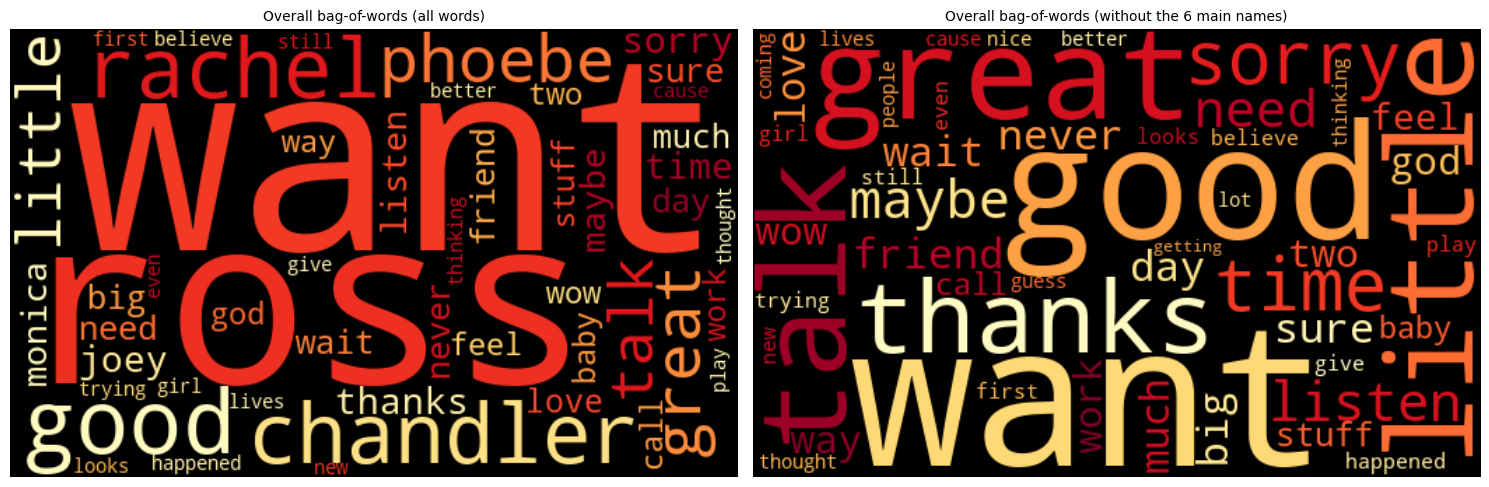

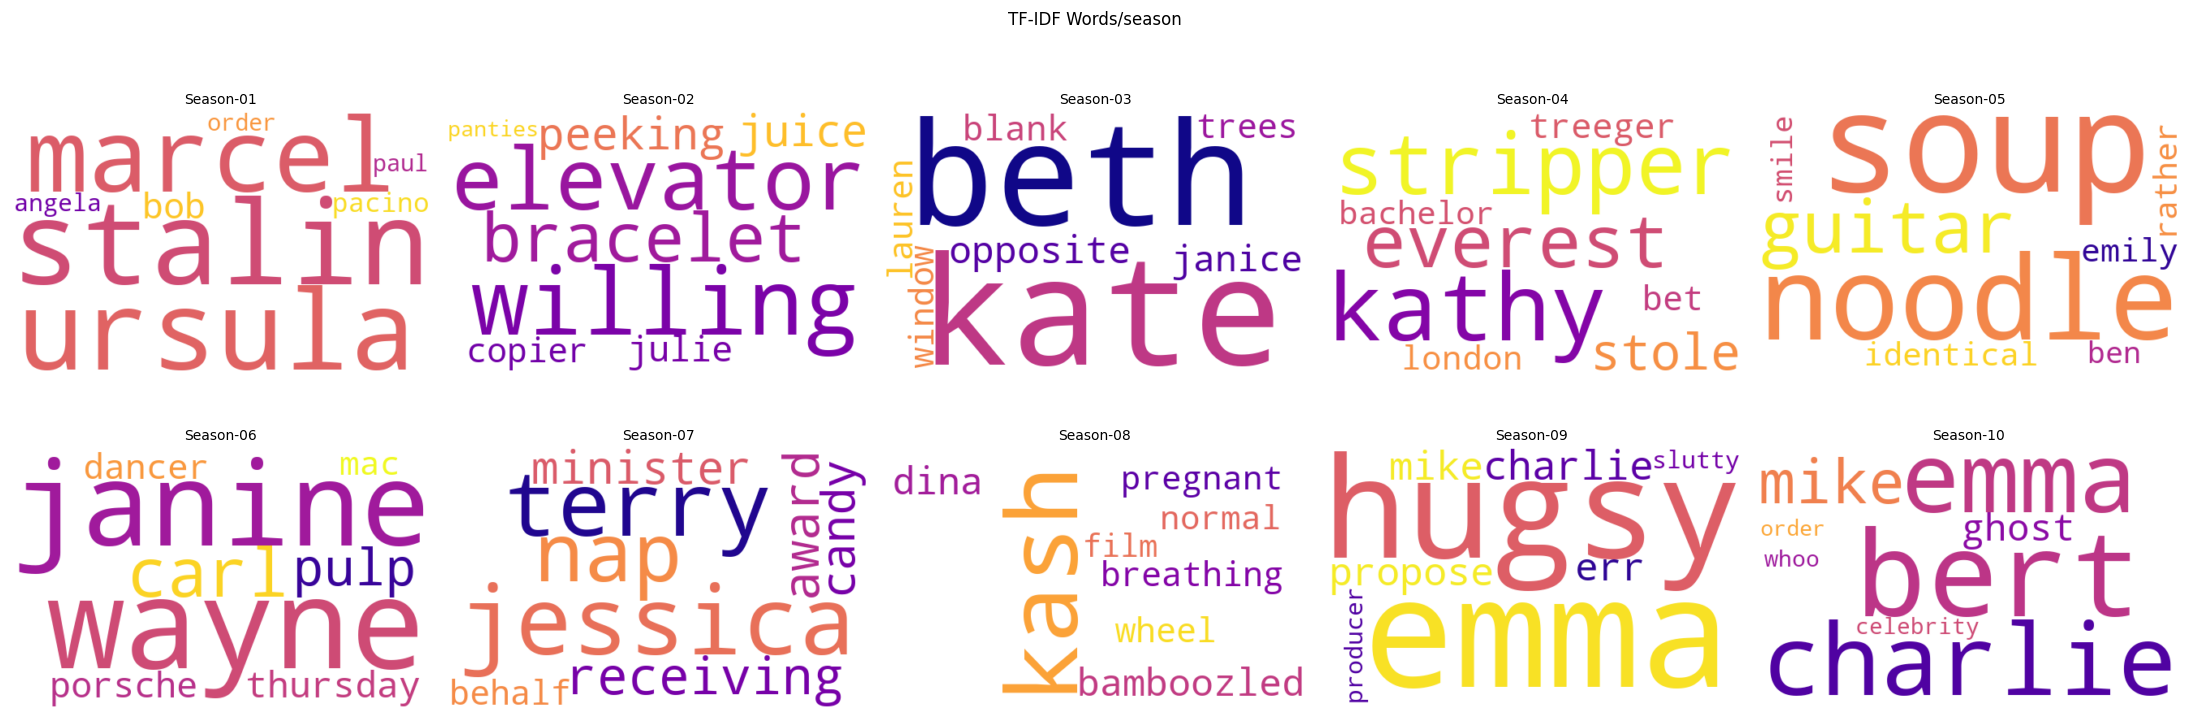

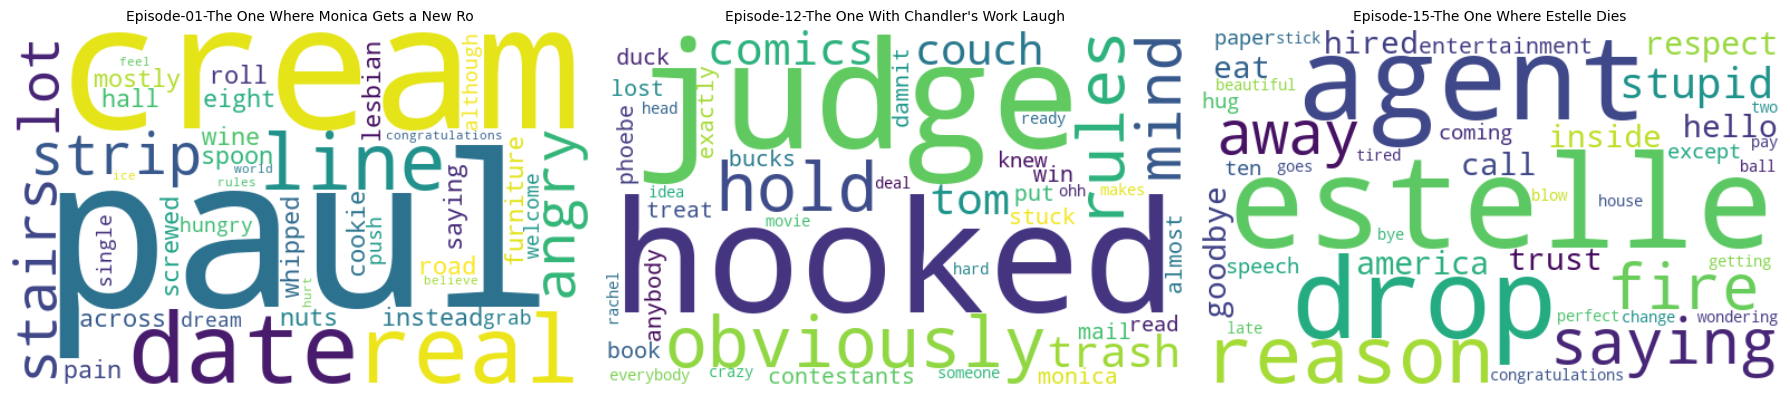

In [6]:
def cloud(ax, freq, title, cmap="viridis", bg="white"):
    wc = WordCloud(width=520, height=320, background_color=bg, colormap=cmap, max_words=50).generate_from_frequencies(freq)
    ax.imshow(wc, interpolation="bilinear"); 
    ax.axis("off"); 
    ax.set_title(title, fontsize=10)

# overall cloud - with and without char names
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
cloud(ax[0], counts_all.head(80).to_dict(), "Overall bag-of-words (all words)", "YlOrRd", "black")
cloud(ax[1], no_main.head(80).to_dict(), "Overall bag-of-words (without the 6 main names)", "YlOrRd", "black")
plt.tight_layout(); 
plt.show()

# one cloud per season (TF-IDF scores)
fig, ax = plt.subplots(2, 5, figsize=(22, 8))
for a, (s, v) in zip(ax.ravel(), season_top.items()): cloud(a, {w: sc for w, sc in v}, s, "plasma")
plt.suptitle("TF-IDF Words/season"); 
plt.tight_layout(); 
plt.show()

# episode cloud
def episode_cloud(season_num, ep_num, ax=None):
    i = ep_docs.index[(ep_docs.season_num == season_num) & (ep_docs.ep_num == ep_num)][0]
    f = {w: sc for w, sc in top_words(Te[i].toarray(), lex_e, 40)}
    if ax is None: fig, ax = plt.subplots(figsize=(6, 4))
    cloud(ax, f, ep_docs.loc[i, "Episode"][:45], "viridis")
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for a, (s, e) in zip(ax, [(1, 1), (5, 12), (10, 15)]): episode_cloud(s, e, a)      
plt.tight_layout(); 
plt.show()

* The most frequent words after removing stopwords and fillers are want, ross, good, rachel, chandler, phoebe, great, little
* names of the friends dominate (Joey talks to and about them) along with conversational verbs/adjectives (want/little/great)
* without the six main names: want, good, great, little, talk, thanks, sorry, time
* TF-IDF with the seasons as documents highlights what is specific to a season (S1:stalin(stage name suggestion),S3:janice(GF),S9: emma(babysitting))
* episode-level TF-IDF isolates episodic plot devices (S1E06: pacino, butt, robe (audition for Al Pacino movie))

1. select the 6 primary speakers 
2. extract and clean speaker names from the raw dataset
3. construct 6 text documents (one per character) by joining stemmed, pre-processed tokens
4. compute TF-IDF across the 6 character docs dropping words used by more than 3 chars (50%)
5. output words with the highest TF-IDF scores specific to Joey


In [7]:
MAIN_SPEAKERS = ["rachel", "ross", "monica", "chandler", "joey", "phoebe"]
spk_all = df_raw["Speaker"].fillna("").str.strip().str.lower()
char_docs = {c: " ".join(" ".join(stemmer.stem(w) for w in q3_tokens(t)) for t in df_raw.loc[spk_all == c, "Text"]) for c in MAIN_SPEAKERS}
Xc, Tc, lex_c = importance(list(char_docs.values()), min_total=5, max_df=0.5)       
joey_i = MAIN_SPEAKERS.index("joey")
print("Typical Joey Words (TF-IDF, characters as documents):", [w for w, _ in top_words(Tc[joey_i].toarray(), lex_c, 20)])

Typical Joey Words (TF-IDF, characters as documents): ['script', 'wayne', 'estelle', 'neurosurgeon', 'blank', 'hugsy', 'dorks', 'shaft', 'ramoray', 'remoray', 'kash', 'angela', 'pacino', 'kate', 'casting', 'clinic', 'pulp', 'err', 'stalin', 'copier']


* treating each character as a document helps isolate words unique to Joey relative to the rest of the cast:
* majority of Joey's unique vocabulary comes from acting: script,estelle(agent),neurosurgeon/ramoray/remoray (Days of Our Lives),casting,pacino)

## Q4. Co-occurrence of words with PPMI

1. extract unstemmed token lists from Joey’s lines
2. count frequencies,filters tokens (>10), create word-to-index lookup mappings, and initialize a zero matrix for co-occurrences
3. go through every tokenized line, sliding a window(5) and increment symmetric co-occurrence counts
4. compute joint and marginal probability matrices (smoothing alpha=1.0)
5. calculate PMI, apply ReLU for positive PMI, and filter pairs under 5
6. extracts upper triangle of the symmetric PPMI matrix to eliminate duplicates
7. output summary stats, associations ranked by PPMI, and co-occurrence frequency

In [8]:
# same tokens as Q3 (stage directions removed, contractions expanded, stopwords removed), NOT stemmed
joey4_tokens = joey3["tokens"]            

def compute_ppmi(token_series, window=5, min_word_freq=10, min_pair_freq=5, alpha=1.0):
    counts = Counter(w for toks in token_series for w in toks)
    vocab = [w for w, c in counts.items() if c >= min_word_freq]; w2i = {w: i for i, w in enumerate(vocab)}; V = len(vocab)
    co = np.zeros((V, V))
    for toks in token_series:                                         
        ids = [w2i[w] for w in toks if w in w2i]                      
        for k, i in enumerate(ids):
            for c in range(max(0, k - window), min(len(ids), k + window + 1)):
                if c != k and ids[c] != i: co[i, ids[c]] += 1        
    total = co.sum(); p_xy = co / total; p_x = co.sum(1) / total      
    ctx = co.sum(0) ** alpha; p_y = ctx / ctx.sum()                  
    with np.errstate(divide="ignore", invalid="ignore"):
        pmi = np.log2(p_xy / np.outer(p_x, p_y))
    pmi[~np.isfinite(pmi)] = 0
    ppmi = np.maximum(pmi, 0)                                       
    ppmi[co < min_pair_freq] = 0                                     
    return pd.DataFrame(ppmi, index=vocab, columns=vocab), pd.DataFrame(co, index=vocab, columns=vocab)

def top_pairs(ppmi, co, k=15, by="PPMI"):
    P, C = ppmi.values, co.values; iu = np.triu_indices(len(P), 1)
    s = P[iu] if by == "PPMI" else np.where(P[iu] > 0, C[iu], 0)      
    o = np.argsort(s)[::-1][:k]
    return pd.DataFrame({"word 1": ppmi.index[iu[0][o]], "word 2": ppmi.index[iu[1][o]], "PPMI": P[iu][o].round(2), "count": C[iu][o].astype(int)})

ppmi4, co4 = compute_ppmi(joey4_tokens)
print(f"vocabulary: {len(ppmi4)} words (frequency >= 10), pairs with PPMI > 0 and count >= 5: {int(np.triu(ppmi4.values > 0, 1).sum())}")
print("\nStrongest associations (PPMI), pair count >= 5"); display(top_pairs(ppmi4, co4, 10, "PPMI"))
print("Most frequent word pairs that are positively associated"); display(top_pairs(ppmi4, co4, 10, "count"))

vocabulary: 531 words (frequency >= 10), pairs with PPMI > 0 and count >= 5: 479

Strongest associations (PPMI), pair count >= 5


,word 1,word 2,PPMI,count
0,lose,bet,8.36,10
1,keys,porsche,8.19,10
2,lying,lie,7.88,7
3,chick,duck,7.85,6
4,hugsy,emma,7.62,7
5,push,ball,7.61,6
6,tickets,knicks,7.42,6
7,five,hundred,7.33,10
8,high,school,7.12,7
9,york,city,7.09,8


Most frequent word pairs that are positively associated


,word 1,word 2,PPMI,count
0,wait,minute,5.51,44
1,ross,rachel,1.72,40
2,lives,days,6.01,30
3,big,deal,4.72,28
4,chandler,monica,2.46,27
5,ross,chandler,0.90,22
6,last,night,4.26,21
7,want,chandler,0.41,19
8,good,luck,4.23,18
9,rachel,friend,2.27,17


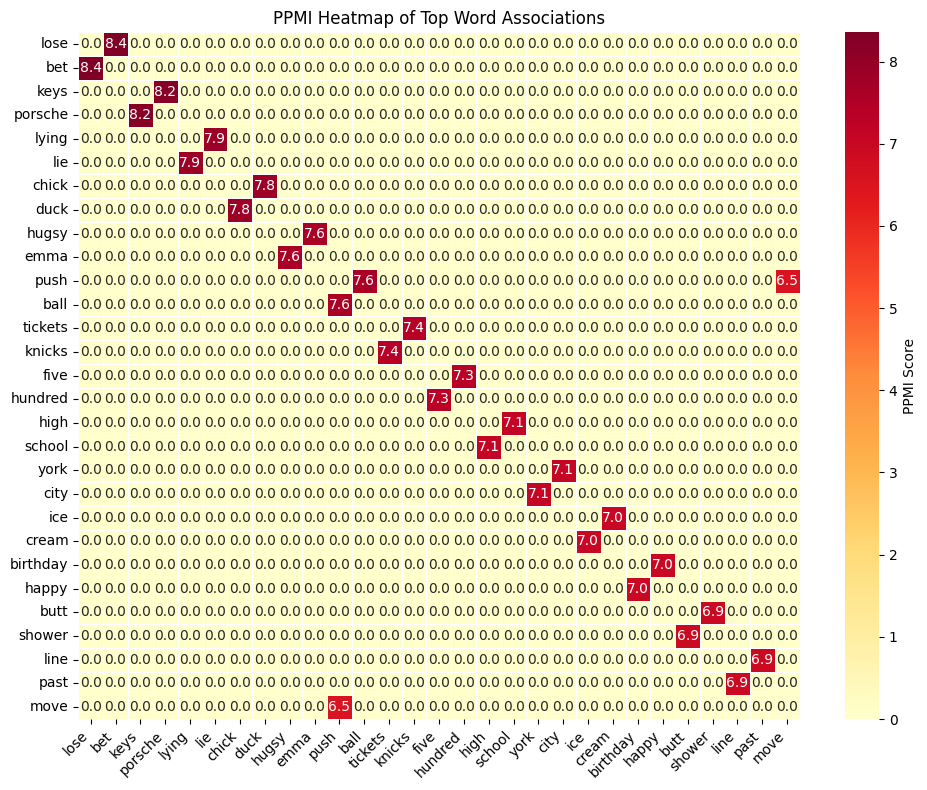

In [9]:
tp = top_pairs(ppmi4, co4, 15, "PPMI")
words = list(dict.fromkeys(tp[["word 1", "word 2"]].values.ravel()))
M_df = ppmi4.loc[words, words]

plt.figure(figsize=(10, 8))
sns.heatmap(M_df, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={'label': 'PPMI Score'}, linewidths=0.5)
plt.title("PPMI Heatmap of Top Word Associations", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

* Joey's words that are used together most strongly are: lose–bet, keys–porsche, lying–lie, chick–duck, hugsy–emma, push–ball, tickets–knicks
* Most of them are fixed expressions or recurring topics of the show.
* Since PPMI favours pairs of rare words, we only report pairs that occur at least 5 times 
* Most frequent associated pairs are listed separately
----------------------------------------------------------------------------------
* 531 words met the frequency threshold (>=10), creating 481 positively associated pairs which are mostly plot devices
* lose – bet (PPMI = 8.36): regarding apartment bets between chandler and joey
* keys – porsche (PPMI = 8.19): Season 6 arc where Joey finds Porsche keys
* hugsy – emma (PPMI = 7.62): sharing stuffed penguin with Rachel’s baby
----------------------------------------------------------------------------------
* highest Co-occurrence count goes to character features
* wait – minute - signature realization phrase 
* lives – days - references to his Days of Our Lives character
* chandler – monica / rachel - ross - discussions regarding relationships between the group